WEATHER DATA ANALYSIS

Setup and load the data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Matplotlib defaults: clean, readable charts without extra styling dependencies
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 110
})


data = pd.read_csv(r"C:\Users\HP\Desktop\Weather Data\Dataset_Weather_Analysis.csv")
print(f"Dataset loaded: {data.shape[0]:,} rows × {data.shape[1]:,} columns")
display(data.head())

Dataset loaded: 8,784 rows × 8 columns


,Date/Time,Temp_C,Dew Point Temp_C,Rel Hum_%,Wind Speed_km/h,Visibility_km,Press_kPa,Weather
0,01-01-2012 00:00,-1.8,-3.9,86,4,8.0,101.24,Fog
1,01-01-2012 01:00,-1.8,-3.7,87,4,8.0,101.24,Fog
2,01-01-2012 02:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog"
3,01-01-2012 03:00,-1.5,-3.2,88,6,4.0,101.27,"Freezing Drizzle,Fog"
4,01-01-2012 04:00,-1.5,-3.3,88,7,4.8,101.23,Fog


Understand the dataset

In [3]:
print("Shape:", data.shape)
print("\\nColumn names:")
print(data.columns.tolist())

print("\\nData types and non-null counts:")
data.info()

display(data.describe(include="all").T)


Shape: (8784, 8)
\nColumn names:
['Date/Time', 'Temp_C', 'Dew Point Temp_C', 'Rel Hum_%', 'Wind Speed_km/h', 'Visibility_km', 'Press_kPa', 'Weather']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date/Time         8784 non-null   str    
 1   Temp_C            8784 non-null   float64
 2   Dew Point Temp_C  8784 non-null   float64
 3   Rel Hum_%         8784 non-null   int64  
 4   Wind Speed_km/h   8784 non-null   int64  
 5   Visibility_km     8784 non-null   float64
 6   Press_kPa         8784 non-null   float64
 7   Weather           8784 non-null   str    
dtypes: float64(4), int64(2), str(2)
memory usage: 549.1 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date/Time,8784,8784,01-01-2012 00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp_C,8784.0,NaN,NaN,NaN,8.798144,11.687883,-23.3,0.1,9.3,18.8,33.0
Dew Point Temp_C,8784.0,NaN,NaN,NaN,2.555294,10.883072,-28.5,-5.9,3.3,11.8,24.4
Rel Hum_%,8784.0,NaN,NaN,NaN,67.431694,16.918881,18.0,56.0,68.0,81.0,100.0
Wind Speed_km/h,8784.0,NaN,NaN,NaN,14.945469,8.688696,0.0,9.0,13.0,20.0,83.0
Visibility_km,8784.0,NaN,NaN,NaN,27.664447,12.622688,0.2,24.1,25.0,25.0,48.3
Press_kPa,8784.0,NaN,NaN,NaN,101.051623,0.844005,97.52,100.56,101.07,101.59,103.65
Weather,8784,50,Mainly Clear,2106,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Data Quality Checks

In [4]:
quality = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2),
    "unique_values": data.nunique(dropna=True),
    "dtype": data.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(quality)
print(f"Duplicate rows: {data.duplicated().sum():,}")


,missing_count,missing_percent,unique_values,dtype
Date/Time,0,0.0,8784,str
Temp_C,0,0.0,533,float64
Dew Point Temp_C,0,0.0,489,float64
Rel Hum_%,0,0.0,83,int64
Wind Speed_km/h,0,0.0,34,int64
Visibility_km,0,0.0,24,float64
Press_kPa,0,0.0,518,float64
Weather,0,0.0,50,str


Duplicate rows: 0


Standardize column names and identify key fields

In [5]:
analysis = data.copy()

# Normalize column labels for easier referencing
analysis.columns = (
    analysis.columns.astype(str)
    .str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
    .str.lower()
)

print("Standardized columns:")
print(analysis.columns.tolist())

def find_column(candidates, columns):
    # Exact normalized match first, then substring match
    for candidate in candidates:
        candidate = candidate.lower()
        if candidate in columns:
            return candidate
    for candidate in candidates:
        candidate = candidate.lower()
        for col in columns:
            if candidate in col:
                return col
    return None

weather_col = find_column(["weather", "weather_condition"], analysis.columns)
temp_col = find_column(["temp_c", "temperature_c", "temperature"], analysis.columns)
humidity_col = find_column(["rel_hum", "relative_humidity", "humidity"], analysis.columns)
wind_col = find_column(["wind_speed_km_h", "wind_speed"], analysis.columns)
visibility_col = find_column(["visibility_km", "visibility"], analysis.columns)
pressure_col = find_column(["press_kpa", "pressure_kpa", "pressure"], analysis.columns)
date_col = find_column(["date_time", "datetime", "date"], analysis.columns)

detected = {
    "Weather condition": weather_col,
    "Temperature": temp_col,
    "Relative humidity": humidity_col,
    "Wind speed": wind_col,
    "Visibility": visibility_col,
    "Pressure": pressure_col,
    "Date/time": date_col
}
display(pd.DataFrame({"Field": detected.keys(), "Detected column": detected.values()}))


Standardized columns:
['date_time', 'temp_c', 'dew_point_temp_c', 'rel_hum', 'wind_speed_km_h', 'visibility_km', 'press_kpa', 'weather']


,Field,Detected column
0,Weather condition,weather
1,Temperature,temp_c
2,Relative humidity,rel_hum
3,Wind speed,wind_speed_km_h
4,Visibility,visibility_km
5,Pressure,press_kpa
6,Date/time,date_time


Prepare fields for analysis

In [6]:
numeric_cols = [c for c in [temp_col, humidity_col, wind_col, visibility_col, pressure_col] if c]
for col in numeric_cols:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")

if date_col:
    analysis[date_col] = pd.to_datetime(analysis[date_col], errors="coerce")

if weather_col:
    analysis[weather_col] = analysis[weather_col].astype("string").str.strip()
    # Standardize capitalization without merging genuinely different labels
    analysis[weather_col] = analysis[weather_col].str.replace(r"\\s+", " ", regex=True)

display(analysis.head())
print("Rows available for analysis:", len(analysis))


,date_time,temp_c,dew_point_temp_c,rel_hum,wind_speed_km_h,visibility_km,press_kpa,weather
0,2012-01-01 00:00:00,-1.8,-3.9,86,4,8.0,101.24,Fog
1,2012-01-01 01:00:00,-1.8,-3.7,87,4,8.0,101.24,Fog
2,2012-01-01 02:00:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog"
3,2012-01-01 03:00:00,-1.5,-3.2,88,6,4.0,101.27,"Freezing Drizzle,Fog"
4,2012-01-01 04:00:00,-1.5,-3.3,88,7,4.8,101.23,Fog


Rows available for analysis: 8784


Weather condition frequency

,observations
weather,
Mainly Clear,2106
Mostly Cloudy,2069
Cloudy,1728
Clear,1326
Snow,390
Rain,306
Rain Showers,188
Fog,150
"Rain,Fog",116


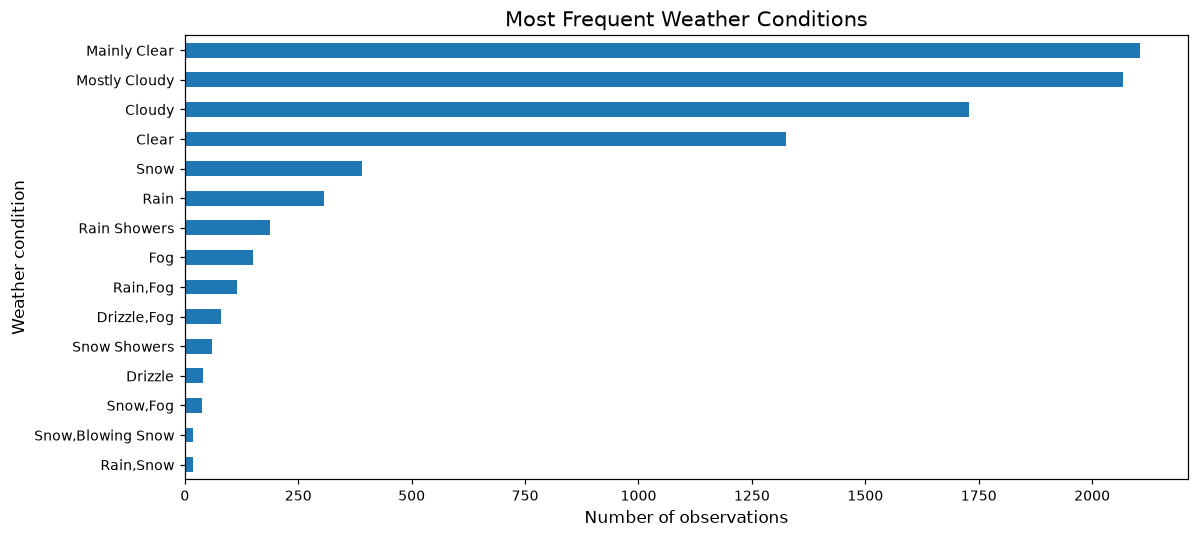

In [7]:
if weather_col:
    weather_counts = analysis[weather_col].value_counts(dropna=False)
    display(weather_counts.rename("observations").to_frame())

    fig, ax = plt.subplots(figsize=(11, 5))
    weather_counts.head(15).sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Most Frequent Weather Conditions")
    ax.set_xlabel("Number of observations")
    ax.set_ylabel("Weather condition")
    fig.tight_layout()
    plt.show()
else:
    print("No weather-condition column detected. Check the column mapping above.")


Temperature Distribution

Mean: 8.80 °C | Median: 9.30 °C | Std. dev.: 11.69 °C | Min: -23.30 °C | Max: 33.00 °C


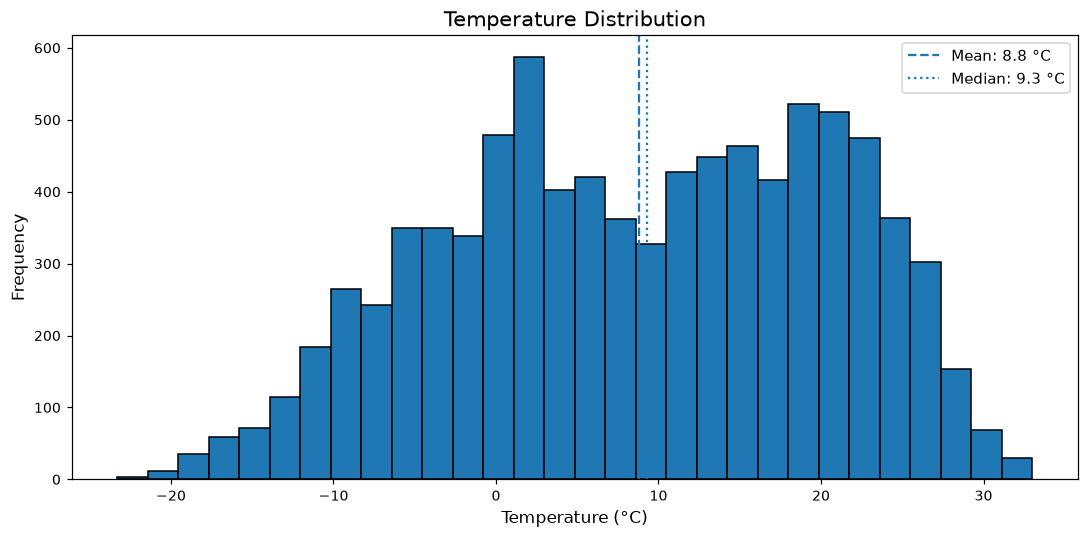

In [8]:
if temp_col:
    temp = analysis[temp_col].dropna()
    if not temp.empty:
        print(f"Mean: {temp.mean():.2f} °C | Median: {temp.median():.2f} °C | "
              f"Std. dev.: {temp.std():.2f} °C | Min: {temp.min():.2f} °C | Max: {temp.max():.2f} °C")
        fig, ax = plt.subplots()
        ax.hist(temp, bins=30, edgecolor="black")
        ax.axvline(temp.mean(), linestyle="--", label=f"Mean: {temp.mean():.1f} °C")
        ax.axvline(temp.median(), linestyle=":", label=f"Median: {temp.median():.1f} °C")
        ax.set_title("Temperature Distribution")
        ax.set_xlabel("Temperature (°C)")
        ax.set_ylabel("Frequency")
        ax.legend()
        fig.tight_layout()
        plt.show()
else:
    print("No temperature column detected.")


Temperature by weather condition

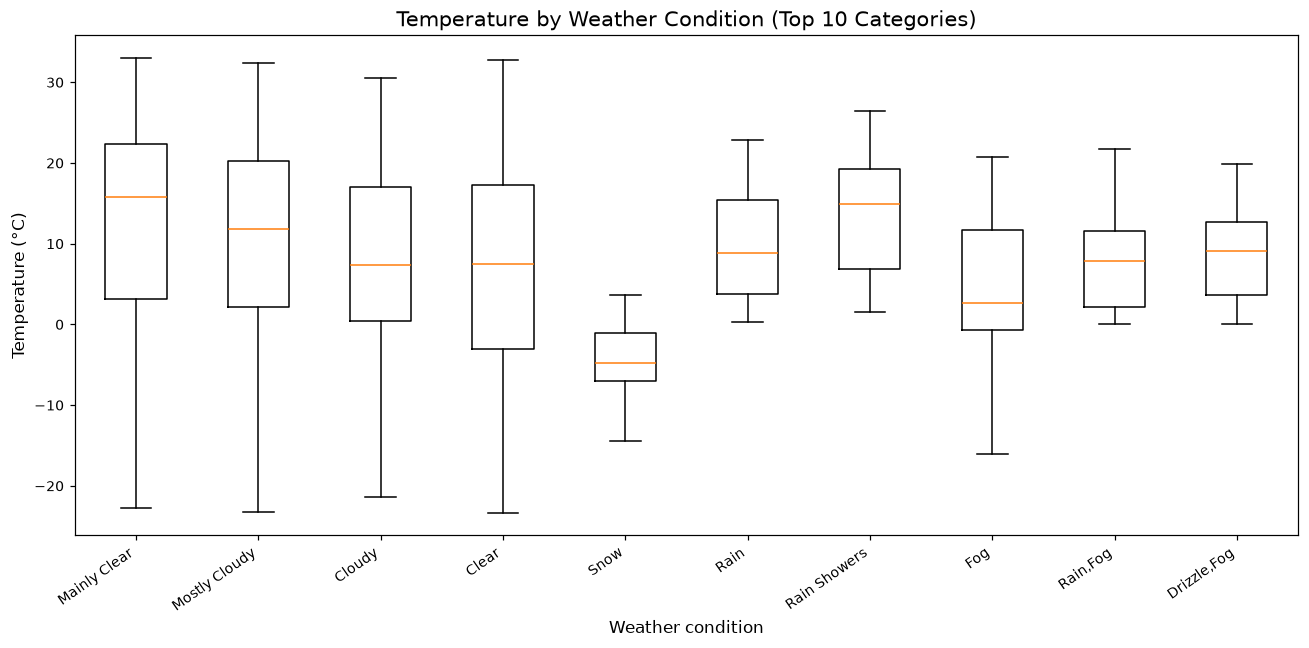

In [9]:
if temp_col and weather_col:
    plot_df = analysis[[weather_col, temp_col]].dropna()
    top_conditions = plot_df[weather_col].value_counts().head(10).index
    plot_df = plot_df[plot_df[weather_col].isin(top_conditions)]
    groups = [plot_df.loc[plot_df[weather_col] == label, temp_col].values
              for label in top_conditions]
    labels = list(top_conditions)
    if groups:
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.boxplot(groups, tick_labels=labels, showfliers=False)
        ax.set_title("Temperature by Weather Condition (Top 10 Categories)")
        ax.set_xlabel("Weather condition")
        ax.set_ylabel("Temperature (°C)")
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
        fig.tight_layout()
        plt.show()
else:
    print("Temperature and/or weather-condition field not detected.")


Humidity ,wind,visibility and pressure

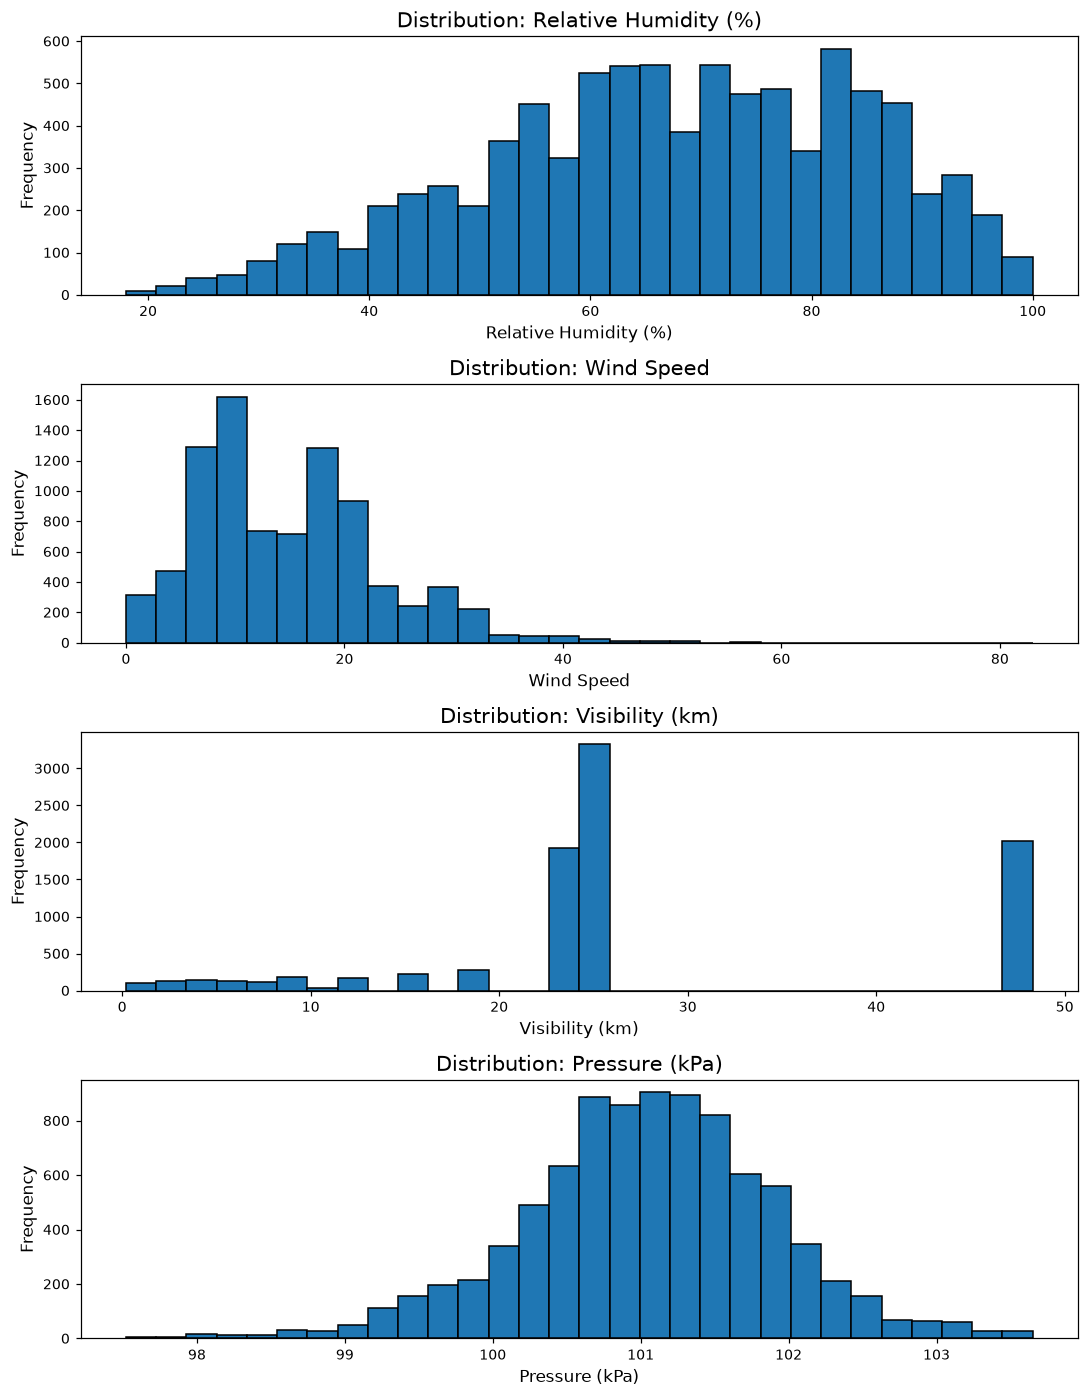

In [10]:
fields_to_plot = [
    (humidity_col, "Relative Humidity (%)"),
    (wind_col, "Wind Speed"),
    (visibility_col, "Visibility (km)"),
    (pressure_col, "Pressure (kPa)")
]
available = [(col, label) for col, label in fields_to_plot if col]
if available:
    fig, axes = plt.subplots(len(available), 1, figsize=(10, 3.2 * len(available)))
    if len(available) == 1:
        axes = [axes]
    for ax, (col, label) in zip(axes, available):
        values = analysis[col].dropna()
        ax.hist(values, bins=30, edgecolor="black")
        ax.set_title(f"Distribution: {label}")
        ax.set_xlabel(label)
        ax.set_ylabel("Frequency")
    fig.tight_layout()
    plt.show()
else:
    print("No humidity, wind, visibility, or pressure fields detected.")


Correlation between numerical weather variables

,temp_c,dew_point_temp_c,rel_hum,wind_speed_km_h,visibility_km,press_kpa
temp_c,1.00,0.93,-0.22,-0.06,0.27,-0.24
dew_point_temp_c,0.93,1.00,0.14,-0.10,0.05,-0.32
rel_hum,-0.22,0.14,1.00,-0.09,-0.63,-0.23
wind_speed_km_h,-0.06,-0.10,-0.09,1.00,0.00,-0.36
visibility_km,0.27,0.05,-0.63,0.00,1.00,0.23
press_kpa,-0.24,-0.32,-0.23,-0.36,0.23,1.00


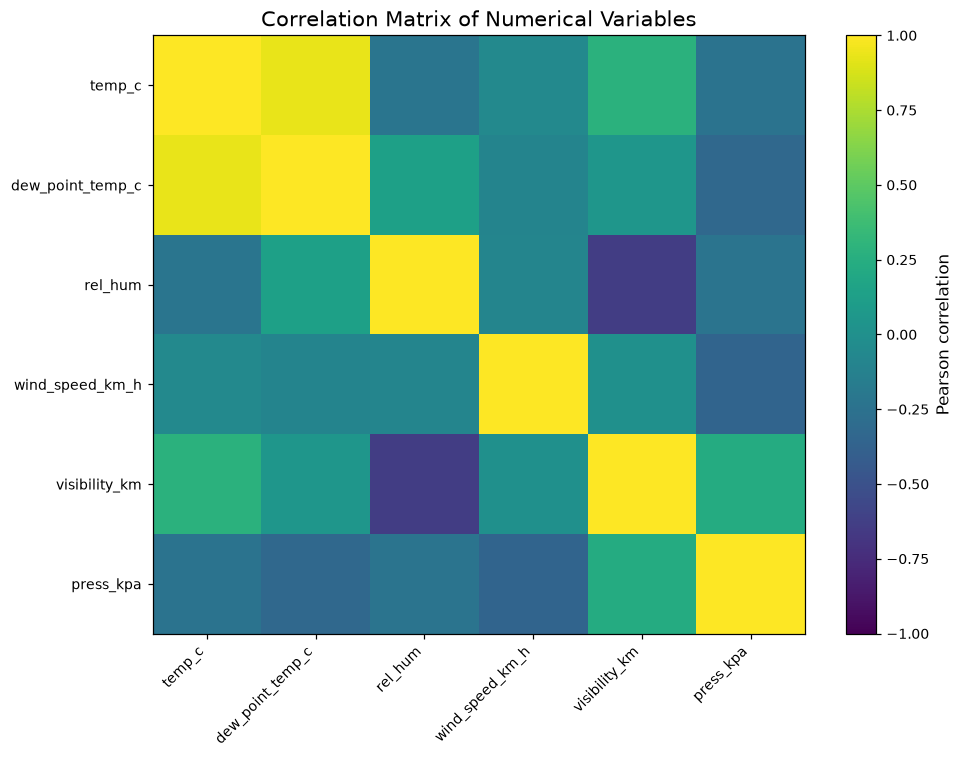

In [11]:
corr_cols = analysis.select_dtypes(include=np.number).columns.tolist()
if len(corr_cols) >= 2:
    corr = analysis[corr_cols].corr(numeric_only=True)
    display(corr.round(2))

    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title("Correlation Matrix of Numerical Variables")
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are required for correlation analysis.")


Relationship between temperature and humidity

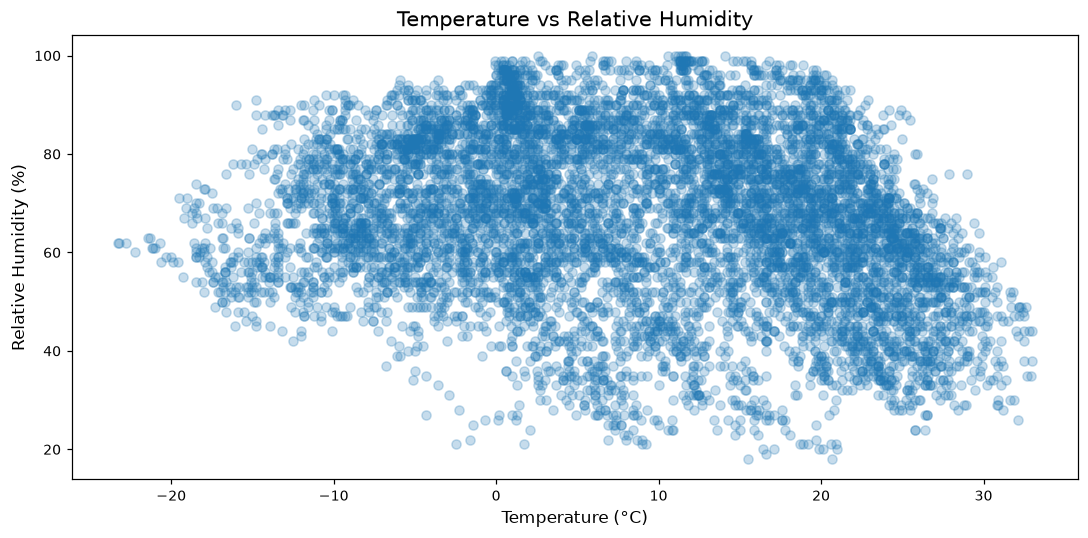

Pearson correlation: -0.22


In [12]:
if temp_col and humidity_col:
    pair = analysis[[temp_col, humidity_col]].dropna()
    if len(pair) > 1:
        fig, ax = plt.subplots()
        ax.scatter(pair[temp_col], pair[humidity_col], alpha=0.25)
        ax.set_title("Temperature vs Relative Humidity")
        ax.set_xlabel("Temperature (°C)")
        ax.set_ylabel("Relative Humidity (%)")
        fig.tight_layout()
        plt.show()
        print("Pearson correlation:", round(pair[temp_col].corr(pair[humidity_col]), 3))
else:
    print("Temperature and humidity fields are required for this chart.")


Visibility by weather condition

,count,mean,median,min,max
weather,,,,,
"Moderate Snow,Blowing Snow",2,0.60,0.60,0.6,0.6
Freezing Fog,4,0.65,0.80,0.2,0.8
Moderate Snow,4,0.75,0.80,0.6,0.8
"Freezing Drizzle,Haze",3,2.67,2.00,2.0,4.0
"Snow,Blowing Snow",19,4.11,2.00,0.6,9.7
"Freezing Rain,Haze",2,2.40,2.40,2.0,2.8
Snow Pellets,1,2.40,2.40,2.4,2.4
"Thunderstorms,Heavy Rain Showers",1,2.40,2.40,2.4,2.4
"Thunderstorms,Moderate Rain Showers,Fog",1,3.20,3.20,3.2,3.2


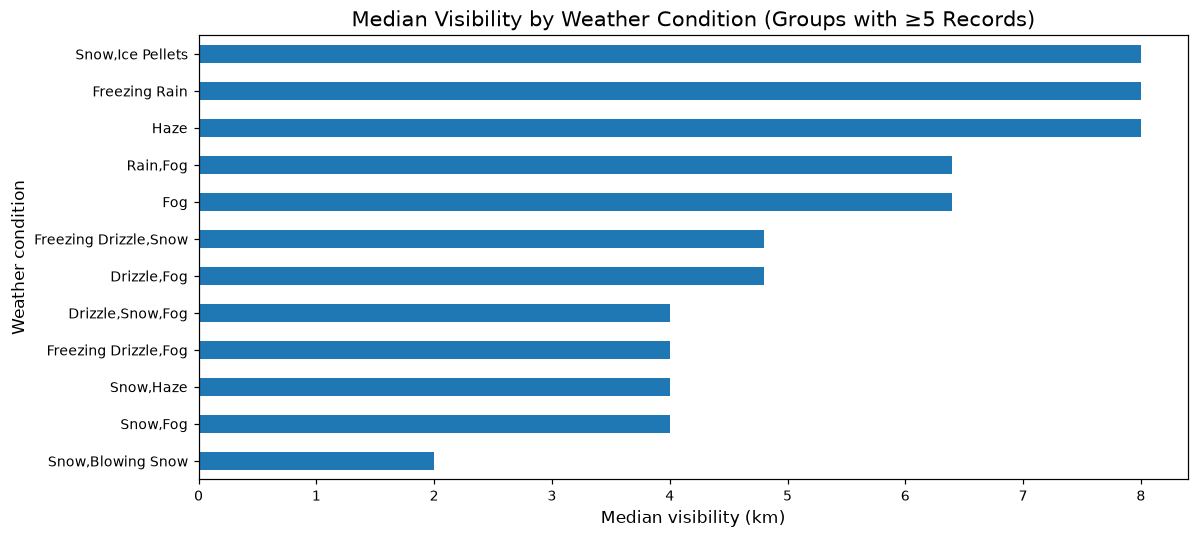

In [13]:
if visibility_col and weather_col:
    visibility_summary = (
        analysis.groupby(weather_col, dropna=False)[visibility_col]
        .agg(["count", "mean", "median", "min", "max"])
        .sort_values("median")
    )
    display(visibility_summary.round(2))

    plot_summary = visibility_summary[visibility_summary["count"] >= 5].head(12)
    if not plot_summary.empty:
        fig, ax = plt.subplots(figsize=(11, 5))
        plot_summary["median"].sort_values().plot(kind="barh", ax=ax)
        ax.set_title("Median Visibility by Weather Condition (Groups with ≥5 Records)")
        ax.set_xlabel("Median visibility (km)")
        ax.set_ylabel("Weather condition")
        fig.tight_layout()
        plt.show()
else:
    print("Visibility and weather-condition fields are required.")


Wind speed by weather condition

,count,mean,median,max
weather,,,,
"Moderate Snow,Blowing Snow",2,40.00,40.0,41
Moderate Snow,4,33.75,35.0,39
Snow Pellets,1,35.00,35.0,35
"Snow,Blowing Snow",19,34.84,35.0,48
"Freezing Rain,Snow Grains",1,32.00,32.0,32
"Freezing Rain,Ice Pellets,Fog",1,28.00,28.0,28
"Rain,Snow Grains",1,26.00,26.0,26
"Rain,Ice Pellets",1,24.00,24.0,24
"Rain,Snow,Ice Pellets",4,23.25,24.0,28


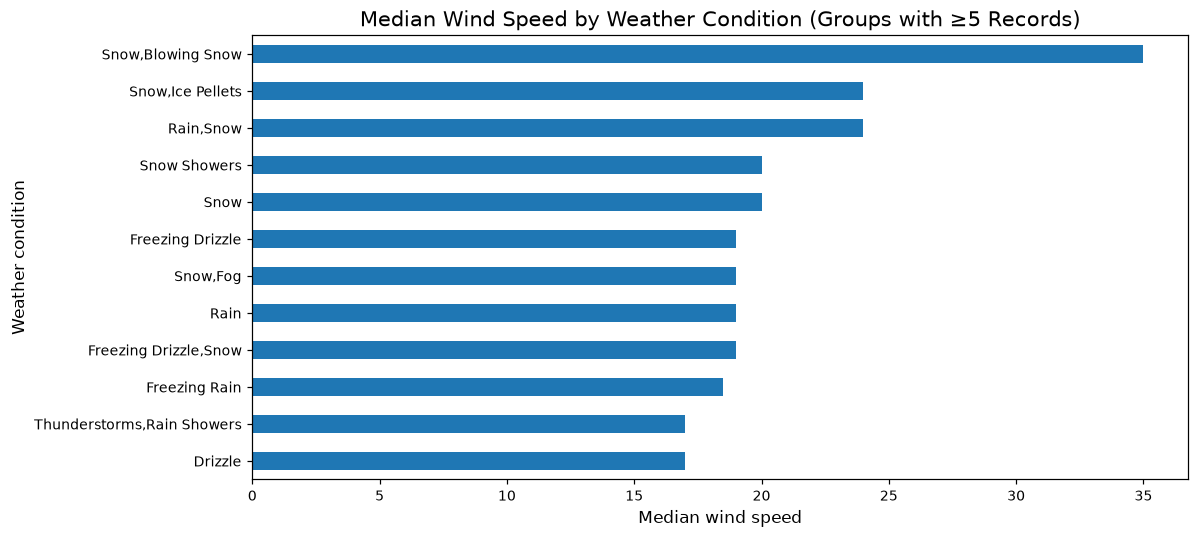

In [14]:
if wind_col and weather_col:
    wind_summary = (
        analysis.groupby(weather_col, dropna=False)[wind_col]
        .agg(["count", "mean", "median", "max"])
        .sort_values("median", ascending=False)
    )
    display(wind_summary.round(2))

    plot_summary = wind_summary[wind_summary["count"] >= 5].head(12)
    if not plot_summary.empty:
        fig, ax = plt.subplots(figsize=(11, 5))
        plot_summary["median"].sort_values().plot(kind="barh", ax=ax)
        ax.set_title("Median Wind Speed by Weather Condition (Groups with ≥5 Records)")
        ax.set_xlabel("Median wind speed")
        ax.set_ylabel("Weather condition")
        fig.tight_layout()
        plt.show()
else:
    print("Wind-speed and weather-condition fields are required.")
